# 04 — Avaliação, calibração e política de crédito
**Modelo:** LightGBM, conjunto A (decisões 3.2 e 3.3), target DPD > 5.
**Fluxo:** (1) calibração (ajustada na validação, confirmada no teste) → (2) métricas com IC 95%, por safra e por tipo de contrato → (3) SHAP → (4) cortes p₁ e p₂ (validação) → (5) faixas A–E → (6) simulação e perda esperada → (7) confirmação no teste → (8) aplicação na submissão e `submissao/previsoes.csv`.
Todos os cortes saem da **validação**; o **teste** só confirma.

In [1]:
import sys, warnings; sys.path.insert(0, '../src')
warnings.filterwarnings('ignore', module='sklearn|lightgbm|shap|pandas')  # avisos de categoria nova (train.preparar) ficam visíveis
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, shap
from IPython.display import display, Markdown
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
import lightgbm as lgb
import train as tr, policy as po
from config import GERADOS, MODELOS, OUTPUTS, SUBMISSAO, RECALL_ALVO, LGD_CENARIOS, SEED
from evaluate import metricas, limiar_max_f1, psi

pd.set_option('display.width', 220, 'display.max_columns', 60)
sns.set_theme(style='whitegrid')
FIG, TAB = OUTPUTS / 'figures', OUTPUTS / 'tables'

R = joblib.load(GERADOS / 'modelos' / 'resultado_nb03.joblib')
ALG, CONJ, modelo, cats = R['ALG'], R['CONJ_FINAL'], R['modelo'], R['cats']
b = pd.read_parquet(GERADOS / 'base_modelagem.parquet'); bs = pd.read_parquet(GERADOS / 'base_submissao_features.parquet')
sp = {s: b[b.split == s].reset_index(drop=True) for s in ['treino', 'valid', 'teste']}
Y = {s: sp[s].target_dpd5.astype(int).values for s in sp}
P = {s: R['S'][ALG, CONJ][s] for s in ['valid', 'teste']}
Xsub = tr.preparar(bs, R['features'], cats)
novas = {c: int((bs[c].notna() & ~bs[c].isin(cats[c])).sum()) for c in cats if c in bs and (bs[c].notna() & ~bs[c].isin(cats[c])).any()}
print('clientes da submissão com categoria fora do treino (viram nulo):', novas or 'nenhum')
P['sub'] = modelo.predict_proba(Xsub)[:, 1]
print(ALG, CONJ, '| AUC valid (confere com nb03):', round(roc_auc_score(Y['valid'], P['valid']), 4), '| submissão:', len(bs), 'clientes')

C:\Projetos\dsaccelerator-tcc\notebooks\../src\train.py:31: UserWarning: tipo_renda: categorias fora do treino viraram nulo: ['Empresário']
  warnings.warn(f"{c}: categorias fora do treino viraram nulo: {sorted(novas)}")


clientes da submissão com categoria fora do treino (viram nulo): {'tipo_renda': 1}


lgbm A | AUC valid (confere com nb03): 0.6992 | submissão: 50000 clientes


## 1. Calibração

A taxa de inadimplência caiu de 25,3% (treino) para 17,6% (validação) e 17,5% (teste), então o score bruto superestima o risco. Compara-se **Platt** (logística sobre o logit, monótona e sem empates) e **isotônica** (mais flexível, mas em degraus). O calibrador é ajustado na **validação** e avaliado no **teste**; a calibração é monótona e não muda a ordenação, apenas a escala em probabilidade.

,calibração,split,brier,ECE,score médio,taxa real,AUC
0,bruto,valid,0.1234,0.0594,0.2224,0.1759,0.6992
1,bruto,teste,0.1236,0.0603,0.2213,0.1747,0.6942
2,platt,valid,0.1206,0.0292,0.1759,0.1759,0.6992
3,platt,teste,0.1208,0.0345,0.1749,0.1747,0.6942
4,isotonica,valid,0.1180,0.0027,0.1759,0.1759,0.6992
5,isotonica,teste,0.1181,0.0101,0.1758,0.1747,0.6942


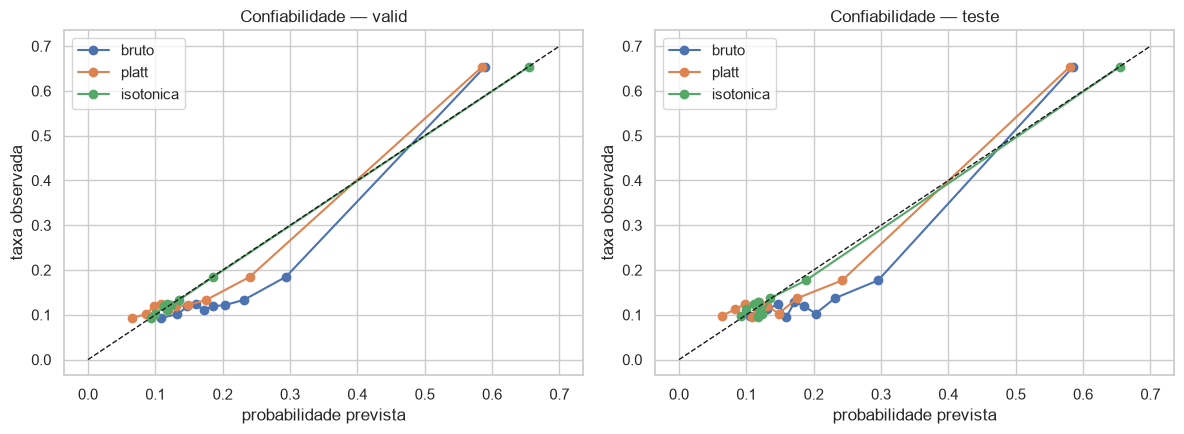

In [2]:
cal = {m: po.Calibrador(m, P['valid'], Y['valid']) for m in ['platt', 'isotonica']}
rows = []
for nome, f in [('bruto', lambda p: p), *cal.items()]:
    for s in ['valid', 'teste']:
        q = f(P[s]); rows.append({'calibração': nome, 'split': s, 'brier': np.mean((q - Y[s]) ** 2), 'ECE': po.ece(Y[s], q),
                                   'score médio': q.mean(), 'taxa real': Y[s].mean(), 'AUC': roc_auc_score(Y[s], q)})
display(pd.DataFrame(rows).round(4))
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for a, s in zip(ax, ['valid', 'teste']):
    for nome, f in [('bruto', lambda p: p), *cal.items()]:
        x, y = calibration_curve(Y[s], f(P[s]), n_bins=10, strategy='quantile')[::-1]
        a.plot(x, y, marker='o', label=nome)
    a.plot([0, .7], [0, .7], 'k--', lw=1); a.set(title=f'Confiabilidade — {s}', xlabel='probabilidade prevista', ylabel='taxa observada'); a.legend()
plt.tight_layout(); plt.savefig(FIG / 'nb04_calibracao.png', dpi=130); plt.show()

**Escolha:** a de menor Brier em validação cruzada **dentro da validação** (a tabela acima mostra o teste só como confirmação). A isotônica cria degraus (empates) que travam os cortes e as faixas; por isso ela recebe um desempate pelo score bruto (1e-6), que preserva a ordenação do modelo. A escolha é registrada em `docs/DECISOES.md`.

In [3]:
# escolha por validação cruzada DENTRO da validação (ajusta em 4 dobras, mede o Brier na 5ª); o teste só confirma
def brier_cv(metodo):
    q = np.zeros(len(Y['valid']))
    for a, b_ in StratifiedKFold(5, shuffle=True, random_state=SEED).split(P['valid'], Y['valid']):
        q[b_] = po.Calibrador(metodo, P['valid'][a], Y['valid'][a])(P['valid'][b_])
    return np.mean((q - Y['valid']) ** 2)
brier_v = {m: brier_cv(m) for m in cal}
METODO = 'platt' if brier_v['platt'] <= brier_v['isotonica'] + 1e-4 else 'isotonica'
print('Brier (validação cruzada na validação):', {k: round(v, 5) for k, v in brier_v.items()}, '->', METODO)
Q = {s: cal[METODO](P[s]) for s in P}

Brier (validação cruzada na validação): {'platt': np.float64(0.12061), 'isotonica': np.float64(0.11855)} -> isotonica


## 2. Métricas e robustez

In [4]:
lim_q = limiar_max_f1(Y['valid'], Q['valid'])
N = 1000
def boot(y, q, lim):
    rng, out = np.random.default_rng(SEED), []
    for _ in range(N):
        i = rng.integers(0, len(y), len(y)); out.append(metricas(y[i], q[i], lim))
    d = pd.DataFrame(out); return d.quantile(.025), d.quantile(.975)
tab = []
for s in ['valid', 'teste']:
    m = pd.Series(metricas(Y[s], Q[s], lim_q)); lo, hi = boot(Y[s], Q[s], lim_q)
    tab.append(pd.DataFrame({'valor': m, 'ic95_inf': lo, 'ic95_sup': hi}).assign(split=s))
tab = pd.concat(tab).reset_index(names='métrica'); tab.to_csv(TAB / 'nb04_metricas_ic.csv', index=False)
print('limiar de máximo F1 (probabilidade calibrada):', round(lim_q, 4)); display(tab.pivot(index='métrica', columns='split').round(4))

limiar de máximo F1 (probabilidade calibrada): 0.25


valor         ic95_inf         ic95_sup        
split            teste   valid    teste   valid    teste   valid
métrica                                                         
auc             0.6942  0.6992   0.6805  0.6886   0.7063  0.7093
brier           0.1181  0.1180   0.1143  0.1147   0.1221  0.1213
f1              0.4771  0.4786   0.4565  0.4618   0.4944  0.4943
f2              0.4196  0.4185   0.3991  0.4017   0.4373  0.4346
gini            0.3885  0.3983   0.3610  0.3771   0.4126  0.4186
ks              0.3437  0.3467   0.3249  0.3299   0.3630  0.3639
pr_auc          0.4346  0.4414   0.4134  0.4238   0.4547  0.4580
precision       0.6182  0.6292   0.5928  0.6091   0.6411  0.6492
recall          0.3884  0.3862   0.3676  0.3695   0.4068  0.4026
taxa_aprovacao  0.8902  0.8920   0.8849  0.8879   0.8957  0.8962

In [5]:
d = pd.concat([sp['valid'].assign(q=Q['valid'], y=Y['valid']), sp['teste'].assign(q=Q['teste'], y=Y['teste'])])
def seg(g):
    return pd.Series({'n': len(g), 'taxa real': g.y.mean(), 'score médio': g.q.mean(),
                      'AUC': roc_auc_score(g.y, g.q) if g.y.nunique() > 1 else np.nan, 'recall (lim F1)': (g.q[g.y == 1] >= lim_q).mean()})
por_safra = d.groupby(['split', d.safra.astype(str).str[:4]]).apply(seg, include_groups=False); por_tipo = d.groupby(['split', 'tipo_contrato']).apply(seg, include_groups=False)
display(por_safra.round(3)); display(por_tipo.round(3))
por_safra.round(4).to_csv(TAB / 'nb04_por_safra.csv'); por_tipo.round(4).to_csv(TAB / 'nb04_por_tipo_contrato.csv')
print('PSI do score calibrado — valid × teste:', round(psi(Q['valid'], Q['teste']), 4), '| teste × submissão:', round(psi(Q['teste'], Q['sub']), 4))

n  taxa real  score médio    AUC  recall (lim F1)
split safra                                                         
teste 2024   13861.0      0.174        0.175  0.693            0.386
      2025     165.0      0.248        0.227  0.738            0.512
valid 2023   22255.0      0.176        0.176  0.699            0.386

n  taxa real  score médio    AUC  recall (lim F1)
split tipo_contrato                                                                   
teste Crédito rotativo          3500.0      0.174        0.173  0.682            0.377
      Empréstimo em dinheiro    5399.0      0.176        0.175  0.696            0.374
      Financiamento de consumo  5127.0      0.173        0.179  0.701            0.412
valid Crédito rotativo          5589.0      0.171        0.174  0.677            0.365
      Empréstimo em dinheiro    8363.0      0.181        0.176  0.707            0.392
      Financiamento de consumo  8303.0      0.175        0.176  0.707            0.394

PSI do score calibrado — valid × teste: 0.003 | teste × submissão: 0.0674


## 3. Explicabilidade (SHAP)

,|SHAP| médio (log-odds)
tipo_organizacao,0.2466
renda_anual,0.1731
qtd_membros_familia,0.1201
ocupacao,0.1188
idade,0.0950
tipo_renda,0.0805
nota_regiao_cliente_cidade,0.0709
nota_regiao_cliente,0.0413
estado_civil,0.0403
qtd_filhos,0.0362


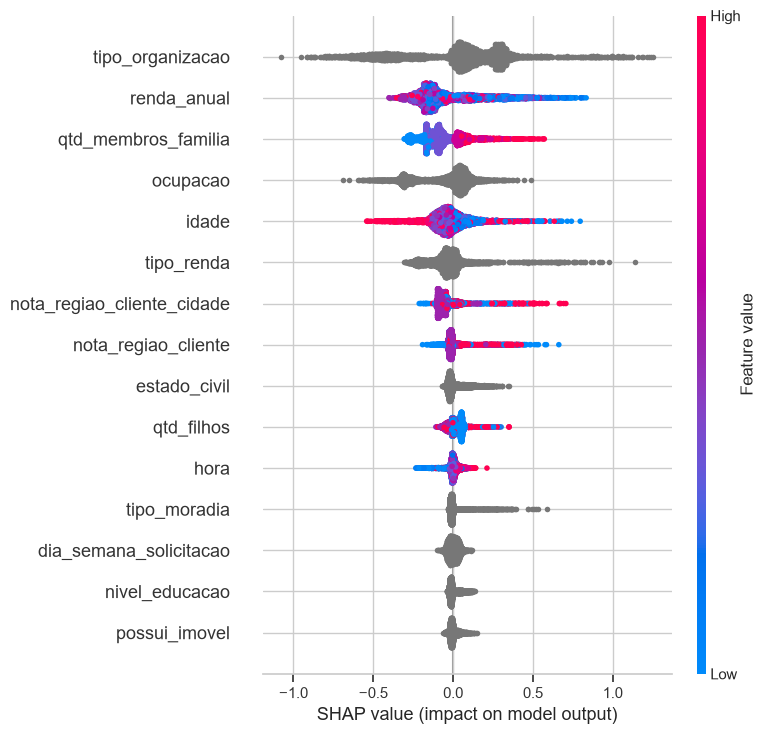

In [6]:
Xv = tr.preparar(sp['valid'], R['features'], cats).sample(5000, random_state=SEED)
sv = shap.TreeExplainer(modelo)(Xv)
vals = sv.values[:, :, 1] if sv.values.ndim == 3 else sv.values
imp = pd.Series(np.abs(vals).mean(0), index=Xv.columns).sort_values(ascending=False)
display(imp.round(4).to_frame('|SHAP| médio (log-odds)'))
shap.summary_plot(vals, Xv, show=False, max_display=15); plt.tight_layout(); plt.savefig(FIG / 'nb04_shap_global.png', dpi=130); plt.show()

In [7]:
# local: um cliente de risco alto e um de risco baixo da amostra
pq = pd.Series(modelo.predict_proba(Xv)[:, 1], index=Xv.index)
for rotulo, i in [('risco alto', pq.idxmax()), ('risco baixo', pq.idxmin())]:
    k = Xv.index.get_loc(i); top = pd.Series(vals[k], index=Xv.columns).reindex(imp.index[:6])
    print(f'{rotulo}: score {pq[i]:.3f}'); display(pd.DataFrame({'valor': Xv.loc[i, top.index].astype(str), 'contribuição (log-odds)': top.round(3)}))

risco alto: score 0.878


,valor,contribuição (log-odds)
tipo_organizacao,Autônomo,0.484
renda_anual,186000.0,0.455
qtd_membros_familia,3.0,0.293
ocupacao,Profissionais de saúde,0.099
idade,58.217659137577,0.373
tipo_renda,Aposentado,0.401


risco baixo: score 0.058


,valor,contribuição (log-odds)
tipo_organizacao,Não informado,0.223
renda_anual,67500.0,-0.089
qtd_membros_familia,1.0,-0.276
ocupacao,NaN,-0.350
idade,66.17111567419576,-0.537
tipo_renda,Aposentado,-0.238


## 4. Cortes p₁ e p₂ (escolhidos na validação)
- **p₁** (fronteira do *aprovar direto*): maior corte para o qual a zona "não aprovar direto" (ajuste + rejeição) captura **≥ 80% dos inadimplentes** (recall-alvo, `config.RECALL_ALVO`).
- **p₂** (fronteira do *rejeitar*): corte de **máximo F1** entre os contratos acima de p₁.
- Entre p₁ e p₂: **aprovar com ajuste**.

In [8]:
p1 = po.corte_p1(Y['valid'], Q['valid'], RECALL_ALVO); p2 = po.corte_p2(Y['valid'], Q['valid'], p1)
res = pd.DataFrame({s: po.resumo_corte(Y[s], Q[s], p1, p2) for s in ['valid', 'teste']})
print(f'p1 = {p1:.4f}  |  p2 = {p2:.4f}'); display(res.round(4))

p1 = 0.1179  |  p2 = 0.2500


,valid,teste
taxa_aprovacao_direta,0.3344,0.3403
taxa_ajuste,0.5576,0.5499
taxa_rejeicao,0.1080,0.1098
inad_aprovados_diretos,0.1052,0.1085
inad_ajuste,0.1305,0.1272
inad_rejeitados,0.6292,0.6182
recall_nao_aprovar,0.8000,0.7887
precision_nao_aprovar,0.2114,0.2089
recall_rejeitar,0.3862,0.3884
precision_rejeitar,0.6292,0.6182


C:\Projetos\dsaccelerator-tcc\notebooks\../src\policy.py:100: RuntimeWarning: Mean of empty slice
  inad_aprovados_diretos=y[aprov].mean(), inad_ajuste=y[barra & ~rej].mean() if (barra & ~rej).any() else np.nan,
C:\Projetos\dsaccelerator-tcc\venv\Lib\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


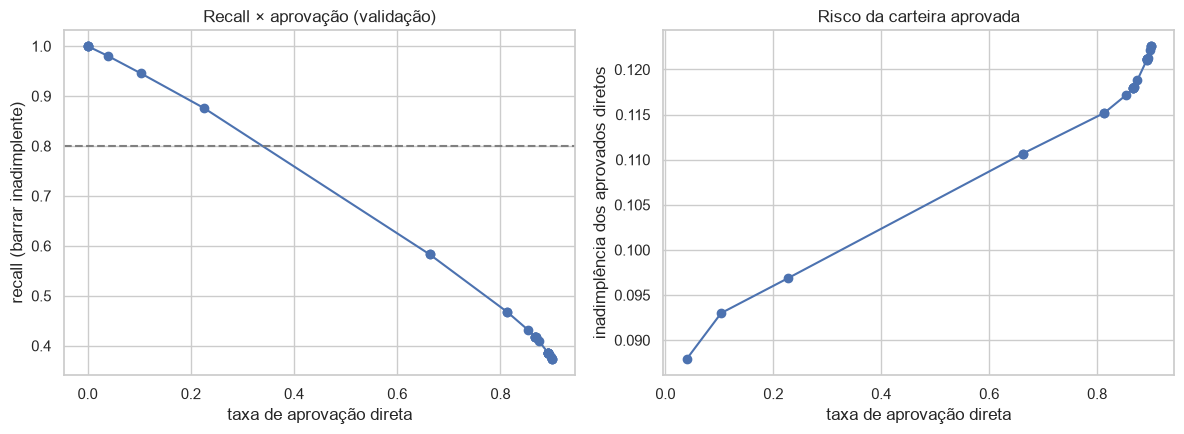

,p1,taxa_aprovacao_direta,inad_aprovados_diretos,recall_nao_aprovar,precision_nao_aprovar,bons_barrados_por_mau_barrado
0,0.05,0.000,NaN,1.000,0.176,4.685
3,0.08,0.000,NaN,1.000,0.176,4.685
6,0.11,0.226,0.097,0.875,0.199,4.024
9,0.14,0.813,0.115,0.467,0.441,1.270
12,0.17,0.867,0.118,0.418,0.555,0.803
15,0.20,0.867,0.118,0.418,0.555,0.803
18,0.23,0.875,0.119,0.409,0.575,0.740
21,0.26,0.893,0.121,0.385,0.633,0.580
24,0.29,0.893,0.121,0.385,0.633,0.580
27,0.32,0.898,0.122,0.377,0.647,0.545


In [9]:
# curva (p1, p2): taxa de aprovação direta × inadimplência dos aprovados × recall × precision
g = []
for t1 in np.linspace(.05, .35, 31):
    r = po.resumo_corte(Y['valid'], Q['valid'], t1, max(t1, p2)); g.append({'p1': t1, **r})
g = pd.DataFrame(g); g.to_csv(TAB / 'nb04_curva_p1.csv', index=False)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(g.taxa_aprovacao_direta, g.recall_nao_aprovar, marker='o'); ax[0].axhline(RECALL_ALVO, ls='--', c='gray')
ax[0].set(xlabel='taxa de aprovação direta', ylabel='recall (barrar inadimplente)', title='Recall × aprovação (validação)')
ax[1].plot(g.taxa_aprovacao_direta, g.inad_aprovados_diretos, marker='o')
ax[1].set(xlabel='taxa de aprovação direta', ylabel='inadimplência dos aprovados diretos', title='Risco da carteira aprovada')
plt.tight_layout(); plt.savefig(FIG / 'nb04_tradeoff_p1.png', dpi=130); plt.show()
display(g.iloc[::3][['p1', 'taxa_aprovacao_direta', 'inad_aprovados_diretos', 'recall_nao_aprovar', 'precision_nao_aprovar', 'bons_barrados_por_mau_barrado']].round(3))

## 5. Faixas A–E (visão de gestão)
**A decisão é tomada só por p₁ e p₂ (3 decisões).** As faixas A–E servem apenas para acompanhamento: A/B dividem a zona "aprovar" e C/D a zona "ajuste" na mediana do volume da validação; E é a rejeição. Verifica-se monotonicidade e o IC de Wilson entre faixas vizinhas.
**Resultado:** as taxas crescem de A a E, mas os ICs de A, B, C (e D no teste) se sobrepõem: com AUC ≈ 0,70 o modelo **não distingue estatisticamente as faixas A–D**; só E se separa. Por isso as faixas não sustentam decisões próprias.

In [10]:
cf = po.cortes_faixas(Q['valid'], p1, p2); print('cortes das faixas:', np.round(cf, 4))
tf = {s: po.tabela_faixas(Y[s], Q[s], cf) for s in ['valid', 'teste']}
for s in tf: print(s); display(tf[s].round(4))
for s in tf: print(s, '| monotônica:', bool(tf[s].taxa.is_monotonic_increasing), '| faixas vizinhas com IC sobreposto:', tf[s].sobrepoe_proxima[:-1].sum())
pd.concat(tf, names=['split']).round(4).to_csv(TAB / 'nb04_faixas.csv')

cortes das faixas: [0.1    0.1179 0.1179 0.25  ]
valid


,n,inad,taxa,ic_inf,ic_sup,decisao,sobrepoe_proxima
f,,,,,,,
A,3721,366,0.0984,0.0892,0.1083,aprovar,True
B,3721,417,0.1121,0.1023,0.1226,aprovar,True
C,6205,731,0.1178,0.1100,0.1261,aprovar com ajuste,False
D,6205,889,0.1433,0.1348,0.1522,aprovar com ajuste,False
E,2403,1512,0.6292,0.6097,0.6483,rejeitar,False


teste


,n,inad,taxa,ic_inf,ic_sup,decisao,sobrepoe_proxima
f,,,,,,,
A,2502,259,0.1035,0.0922,0.1161,aprovar,True
B,2271,259,0.1140,0.1016,0.1278,aprovar,True
C,3898,459,0.1178,0.1080,0.1282,aprovar com ajuste,True
D,3815,522,0.1368,0.1263,0.1481,aprovar com ajuste,False
E,1540,952,0.6182,0.5937,0.6421,rejeitar,False


valid | monotônica: True | faixas vizinhas com IC sobreposto: 2
teste | monotônica: True | faixas vizinhas com IC sobreposto: 3


## 6. Simulação e perda esperada
**EL = PD × LGD × EAD**, com PD calibrada, EAD = `valor_credito` e **LGD como premissa** (45%, 60%, 75%): os dados não trazem recuperação. Compara-se a carteira sem política (aprovar tudo) com a política: aprovar direto (A/B), aprovar com ajuste (C/D, exposição **sem** redução: o efeito do ajuste não é medido) e rejeitar (E, exposição zero).

In [11]:
sim = []
for s in ['valid', 'teste']:
    ead, q = sp[s].valor_credito.values, Q[s]; y = Y[s]
    for lgd in LGD_CENARIOS:
        el_tudo = po.perda_esperada(q, ead, lgd); el_pol = po.perda_esperada(q, ead, lgd, q < p2)
        el_dir = po.perda_esperada(q, ead, lgd, q < p1)
        perda_real = ((y * ead)[q < p2].sum()) * lgd
        sim.append({'split': s, 'LGD': lgd, 'EL aprovar tudo': el_tudo, 'EL com política (A–D)': el_pol, 'EL só aprovados diretos (A/B)': el_dir,
                    'redução da EL (política)': 1 - el_pol / el_tudo, 'perda observada (A–D)': perda_real,
                    '% do crédito rejeitado': ead[q >= p2].sum() / ead.sum()})
sim = pd.DataFrame(sim); sim.to_csv(TAB / 'nb04_simulacao_el.csv', index=False)
display(sim.round(3))

,split,LGD,EL aprovar tudo,EL com política (A–D),EL só aprovados diretos (A/B),redução da EL (política),perda observada (A–D),% do crédito rejeitado
0,valid,0.45,4.532126e+08,3.146352e+08,1.114654e+08,0.306,2.614293e+08,0.078
1,valid,0.60,6.042834e+08,4.195135e+08,1.486206e+08,0.306,3.485724e+08,0.078
2,valid,0.75,7.553543e+08,5.243919e+08,1.857757e+08,0.306,4.357155e+08,0.078
3,teste,0.45,2.597962e+08,1.690814e+08,6.170088e+07,0.349,1.226946e+08,0.093
4,teste,0.60,3.463949e+08,2.254418e+08,8.226784e+07,0.349,1.635928e+08,0.093
5,teste,0.75,4.329936e+08,2.818023e+08,1.028348e+08,0.349,2.044910e+08,0.093


## 7. Confirmação no teste
As métricas do par (p₁, p₂) no teste devem ficar dentro do IC 95% da validação (bootstrap).

In [12]:
def boot_pol(s):
    rng, out = np.random.default_rng(SEED), []; y, q = Y[s], Q[s]
    for _ in range(N):
        i = rng.integers(0, len(y), len(y)); out.append(po.resumo_corte(y[i], q[i], p1, p2))
    d = pd.DataFrame(out); return d.quantile(.025), d.quantile(.975)
lo, hi = boot_pol('valid')
chk = pd.DataFrame({'validação': res.valid, 'IC inf': lo, 'IC sup': hi, 'teste': res.teste})
chk['teste dentro do IC'] = (chk.teste >= chk['IC inf']) & (chk.teste <= chk['IC sup'])
display(chk.round(4)); chk.round(4).to_csv(TAB / 'nb04_confirmacao_teste.csv')

,validação,IC inf,IC sup,teste,teste dentro do IC
taxa_aprovacao_direta,0.3344,0.3279,0.3406,0.3403,True
taxa_ajuste,0.5576,0.5513,0.5638,0.5499,False
taxa_rejeicao,0.1080,0.1038,0.1121,0.1098,True
inad_aprovados_diretos,0.1052,0.0983,0.1123,0.1085,True
inad_ajuste,0.1305,0.1243,0.1361,0.1272,True
inad_rejeitados,0.6292,0.6091,0.6492,0.6182,True
recall_nao_aprovar,0.8000,0.7873,0.8123,0.7887,True
precision_nao_aprovar,0.2114,0.2048,0.2179,0.2089,True
recall_rejeitar,0.3862,0.3695,0.4026,0.3884,True
precision_rejeitar,0.6292,0.6091,0.6492,0.6182,True


### Clientes já vistos no treino × clientes novos
Muitos contratos de validação e teste são de clientes que já aparecem no treino (com outros contratos). Como as variáveis são de cadastro, o modelo pode "reconhecer" o cliente. Comparam-se os dois grupos com o mesmo par (p₁, p₂).

In [13]:
vistos = set(sp['treino'].id_cliente); lin = {}
for s in ['valid', 'teste']:
    visto = sp[s].id_cliente.isin(vistos).values
    for nome, m in [('cliente já visto', visto), ('cliente novo', ~visto)]:
        r = po.resumo_corte(Y[s][m], Q[s][m], p1, p2)
        lin[s, nome] = {'n': int(m.sum()), 'taxa real': Y[s][m].mean(), 'AUC': roc_auc_score(Y[s][m], Q[s][m]),
                        'aprovação direta': r['taxa_aprovacao_direta'], 'recall (não aprovar direto)': r['recall_nao_aprovar'], 'rejeição': r['taxa_rejeicao']}
vn = pd.DataFrame(lin).T; display(vn.round(4)); vn.round(4).to_csv(TAB / 'nb04_clientes_vistos_novos.csv')
print('clientes da submissão que já aparecem no treino:', round(bs.id_cliente.isin(vistos).mean(), 3))

n  taxa real     AUC  aprovação direta  recall (não aprovar direto)  rejeição
valid cliente já visto  14133.0     0.1535  0.7131            0.3581                       0.7995    0.1034
      cliente novo       8122.0     0.2148  0.6738            0.2932                       0.8006    0.1159
teste cliente já visto   7842.0     0.1438  0.7491            0.3548                       0.8236    0.1150
      cliente novo       6184.0     0.2139  0.6396            0.3220                       0.7589    0.1032

clientes da submissão que já aparecem no treino: 0.647


## 8. Fichas de decisão

In [14]:
def ficha(nome, o_que, criterio, linhas):
    t = f'**{nome}**\n\n1. **O que foi decidido:** {o_que}\n2. **Critério:** {criterio}\n'
    return t + '\n'.join(linhas)
rv, rt = res.valid, res.teste
alvo_ok = f"recall de 'não aprovar direto' = {rv.recall_nao_aprovar:.1%} (validação) e {rt.recall_nao_aprovar:.1%} (teste)"
display(Markdown(ficha('p₁ — fronteira do aprovar direto', f'p₁ = {p1:.3f} (probabilidade calibrada)', f'menor risco aceito em aprovação direta com {RECALL_ALVO:.0%} de recall-alvo',
 [f"3. **Números:** aprova direto {rv.taxa_aprovacao_direta:.1%} (valid) / {rt.taxa_aprovacao_direta:.1%} (teste); inadimplência dos aprovados diretos {rv.inad_aprovados_diretos:.1%} / {rt.inad_aprovados_diretos:.1%}; {alvo_ok}.",
  f"4. **Alternativas:** a curva da seção 4 mostra o custo de cada p₁ vizinho em aprovação e recall.",
  f"5. **Trade-off:** {rv.bons_barrados_por_mau_barrado:.1f} bons clientes barrados do aprovar-direto para cada inadimplente (validação).",
  f"6. **Impacto:** ver seção 6 (EL sob LGD de 45/60/75%).",
  "7. **Riscos:** deriva da taxa de inadimplência (25,3% → 17,5%), viés de seleção (só aprovados), efeito dos ajustes não medido; revisar a cada safra nova com PSI > 0,10."])))
display(Markdown(ficha('p₂ — fronteira do rejeitar', f'p₂ = {p2:.3f}', 'máximo F1 entre os contratos acima de p₁',
 [f"3. **Números:** rejeita {rv.taxa_rejeicao:.1%} (valid) / {rt.taxa_rejeicao:.1%} (teste); inadimplência dos rejeitados {rv.inad_rejeitados:.1%} / {rt.inad_rejeitados:.1%}; precision {rv.precision_rejeitar:.1%} / {rt.precision_rejeitar:.1%}; recall {rv.recall_rejeitar:.1%} / {rt.recall_rejeitar:.1%}.",
  "4. **Alternativas:** p₂ maior rejeita menos e com mais certeza; p₂ menor barra mais maus, mas recusa mais bons clientes.",
  f"5. **Trade-off:** inadimplência dos rejeitados é {rv.inad_rejeitados / Y['valid'].mean():.1f}x a média da base.",
  "6. **Impacto:** ver seção 6.", "7. **Riscos:** os rejeitados deixam de gerar desfecho observável (reject inference fora do escopo)."])))

**p₁ — fronteira do aprovar direto**

1. **O que foi decidido:** p₁ = 0.118 (probabilidade calibrada)
2. **Critério:** menor risco aceito em aprovação direta com 80% de recall-alvo
3. **Números:** aprova direto 33.4% (valid) / 34.0% (teste); inadimplência dos aprovados diretos 10.5% / 10.9%; recall de 'não aprovar direto' = 80.0% (validação) e 78.9% (teste).
4. **Alternativas:** a curva da seção 4 mostra o custo de cada p₁ vizinho em aprovação e recall.
5. **Trade-off:** 3.7 bons clientes barrados do aprovar-direto para cada inadimplente (validação).
6. **Impacto:** ver seção 6 (EL sob LGD de 45/60/75%).
7. **Riscos:** deriva da taxa de inadimplência (25,3% → 17,5%), viés de seleção (só aprovados), efeito dos ajustes não medido; revisar a cada safra nova com PSI > 0,10.

**p₂ — fronteira do rejeitar**

1. **O que foi decidido:** p₂ = 0.250
2. **Critério:** máximo F1 entre os contratos acima de p₁
3. **Números:** rejeita 10.8% (valid) / 11.0% (teste); inadimplência dos rejeitados 62.9% / 61.8%; precision 62.9% / 61.8%; recall 38.6% / 38.8%.
4. **Alternativas:** p₂ maior rejeita menos e com mais certeza; p₂ menor barra mais maus, mas recusa mais bons clientes.
5. **Trade-off:** inadimplência dos rejeitados é 3.6x a média da base.
6. **Impacto:** ver seção 6.
7. **Riscos:** os rejeitados deixam de gerar desfecho observável (reject inference fora do escopo).

## 9. Aplicação na submissão

In [15]:
sub = pd.DataFrame({'id_cliente': bs.id_cliente.values, 'probabilidade': Q['sub']})
sub['faixa_gestao'] = po.faixa(sub.probabilidade, cf).values; sub['decisao'] = sub.faixa_gestao.map(po.DECISAO)
assert sub.id_cliente.is_unique and len(sub) == bs.id_cliente.nunique()
SUBMISSAO.mkdir(exist_ok=True); sub[['id_cliente', 'probabilidade', 'decisao', 'faixa_gestao']].to_csv(SUBMISSAO / 'previsoes.csv', index=False)
dec = pd.DataFrame({'submissão': sub.decisao.value_counts(normalize=True),
                    'teste': po.faixa(Q['teste'], cf).map(po.DECISAO).value_counts(normalize=True),
                    'validação': po.faixa(Q['valid'], cf).map(po.DECISAO).value_counts(normalize=True)})
display(dec.round(4))
print('PSI do score (teste × submissão):', round(psi(Q['teste'], Q['sub']), 4), '| probabilidade média submissão × teste:', round(sub.probabilidade.mean(), 4), '×', round(Q['teste'].mean(), 4))

,submissão,teste,validação
aprovar com ajuste,0.5070,0.5499,0.5576
aprovar,0.2941,0.3403,0.3344
rejeitar,0.1989,0.1098,0.1080


PSI do score (teste × submissão): 0.0674 | probabilidade média submissão × teste: 0.2251 × 0.1758


## 10. Por que a submissão parece mais arriscada?
Três verificações, todas na escala das variáveis do modelo (teste × submissão):
1. **PSI por variável:** alguma variável mudou de distribuição?
2. **Diferença média de contribuição SHAP** (submissão − teste, em log-odds): quais variáveis empurram o risco para cima?
3. **Validação adversarial:** um classificador tenta distinguir teste de submissão; AUC 0,5 = indistinguíveis, perto de 1 = populações bem diferentes.

In [16]:
te, F = sp['teste'], R['features']
Xt = tr.preparar(te, F, cats).sample(5000, random_state=SEED); Xs = Xsub.sample(5000, random_state=SEED)
ex = shap.TreeExplainer(modelo)
contrib = lambda X: (lambda v: v[:, :, 1] if v.ndim == 3 else v)(ex(X).values)
desvio = pd.Series(contrib(Xs).mean(0) - contrib(Xt).mean(0), index=F)
shift = pd.DataFrame({'PSI': {f: psi(te[f], bs[f]) for f in F}, 'Δ SHAP médio (log-odds)': desvio}).sort_values('Δ SHAP médio (log-odds)', key=abs, ascending=False)
display(shift.round(4)); shift.round(4).to_csv(TAB / 'nb04_shift_submissao.csv')
print('soma das diferenças de contribuição (log-odds):', round(desvio.sum(), 3))
Xadv = pd.concat([tr.preparar(te, F, cats), Xsub]); yadv = np.r_[np.zeros(len(te)), np.ones(len(bs))]
padv = cross_val_predict(lgb.LGBMClassifier(n_estimators=200, learning_rate=.05, verbose=-1, random_state=SEED), Xadv, yadv,
                         cv=StratifiedKFold(5, shuffle=True, random_state=SEED), method='predict_proba')[:, 1]
print('AUC adversarial (teste × submissão):', round(roc_auc_score(yadv, padv), 3))

,PSI,Δ SHAP médio (log-odds)
renda_anual,0.0047,0.0451
tipo_organizacao,0.0108,0.0346
ocupacao,0.0090,0.0229
tipo_renda,0.0060,0.0227
nota_regiao_cliente,0.0007,0.0177
nota_regiao_cliente_cidade,0.0005,0.0148
idade,0.0101,0.0121
qtd_membros_familia,0.0019,0.0118
estado_civil,0.0020,0.0064
qtd_filhos,0.0014,0.0049


soma das diferenças de contribuição (log-odds): 0.204


AUC adversarial (teste × submissão): 0.613


## 11. Modelo final
O modelo, o calibrador e os cortes ficam juntos em `models/modelo_final.joblib`, para pontuar novos clientes sem rodar os notebooks (uso no README).

In [17]:
import importlib.metadata as im
MODELOS.mkdir(exist_ok=True)
joblib.dump({'versoes': {p: im.version(p) for p in ['lightgbm', 'scikit-learn', 'pandas', 'numpy']},
             'algoritmo': ALG, 'conjunto': CONJ, 'modelo': modelo, 'calibrador': cal[METODO], 'metodo_calibracao': METODO,
             'features': R['features'], 'categorias': cats, 'p1': p1, 'p2': p2, 'cortes_faixas': cf,
             'hiperparametros': R['T'][ALG, CONJ]['params'], 'n_arvores': R['T'][ALG, CONJ]['n_arvores'],
             'metricas': tab.pivot(index='métrica', columns='split', values='valor').loc[['auc', 'f1', 'recall', 'brier']].round(4).to_dict()},
            MODELOS / 'modelo_final.joblib')
print('salvo:', MODELOS / 'modelo_final.joblib', round((MODELOS / 'modelo_final.joblib').stat().st_size / 1e6, 1), 'MB')

salvo: C:\Projetos\dsaccelerator-tcc\models\modelo_final.joblib 1.7 MB


### Leitura
- **Calibração:** o score bruto superestima o risco (média 0,22 contra 17,5% observado). A isotônica, com desempate pelo score bruto, calibra melhor (Brier 0,1181 contra 0,1208 da Platt no teste).
- **Desempenho:** AUC 0,69–0,70 (IC 95% de ±0,012), estável entre 2023 e 2024 e entre os tipos de contrato (crédito rotativo é o pior, AUC ≈ 0,68).
- **Política (3 decisões):** p₁ = 0,118 e p₂ = 0,250. Na validação, 33% são aprovados direto (inadimplência 10,5%), 56% aprovados com ajuste (13,1%) e 11% rejeitados (62,9%). O recall de "não aprovar direto" é 80,0% na validação e 78,9% no teste (dentro do IC). Custo: ≈ 3,7 bons clientes barrados por inadimplente.
- **Faixas A–E:** só visão de gestão; A–D não se distinguem estatisticamente (ICs de Wilson sobrepostos), apenas E se separa.
- **Submissão:** PSI do score 0,067 (< 0,25), mas rejeição de 19,9% contra 11,0% no teste e probabilidade média de 0,225 contra 0,176. Nenhuma variável isolada mudou (PSI máximo 0,04); o risco maior vem de pequenos deslocamentos em várias variáveis (soma +0,20 log-odds, sobretudo renda, organização e ocupação), e o AUC adversarial de 0,61 indica uma diferença moderada de perfil.
  Não dá para separar mudança real de perfil de efeito de seleção (o modelo só viu contratos aprovados); a taxa de rejeição da submissão é uma estimativa que supõe que a relação perfil → risco se mantém. **Alerta registrado.**
- **Limites:** a perda esperada depende da LGD (premissa) e o efeito dos ajustes não foi medido.